In [5]:
import astropy.units as u
import astropy.constants as cst
import numpy as np

print(cst.G)
print((cst.G).to(u.pc * u.M_sun**-1 * u.km**2 * u.s**-2))
print(4*np.pi/(cst.G).to(u.AU * u.M_sun**-1 * u.AU**2 * u.yr**-2))

  Name   = Gravitational constant
  Value  = 6.6743e-11
  Uncertainty  = 1.5e-15
  Unit  = m3 / (kg s2)
  Reference = CODATA 2018
0.00430091727003628 km2 pc / (solMass s2)
0.318321909973388 yr2 solMass / AU3


In [12]:
import astropy.units as u
import astropy.constants as cst
import numpy as np
rho_0 = 1*u.g/u.cm**-3
R_s = 1*u.kpc

def NFW_pot(r):
    return -4*np.pi*cst.G*rho_0*R_s**3/r * np.log(1+r/R_s)
def NFW_v_circ(r):
    return np.sqrt(r*4*np.pi*cst.G*rho_0*R_s**3 * ((r+R_s) * np.log(1+r/R_s)-r) / (r*(r+R_s)))

def NFW_v_esc(r):
    return np.sqrt(-2*NFW_pot(r))


Rs = np.linspace(0,1,1000)*u.kpc

import matplotlib.pyplot as plt
plt.plot(Rs, NFW_v_circ(Rs).to(u.km/u.s), ls="-", color="black", marker="None")
plt.xlabel(r"r/R_s", fontsize=15)
plt.show()

UnitConversionError: 'cm(3/2) kpc(3/2) m(3/2) g(1/2) / (kg(1/2) s)' and 'km / s' (speed/velocity) are not convertible

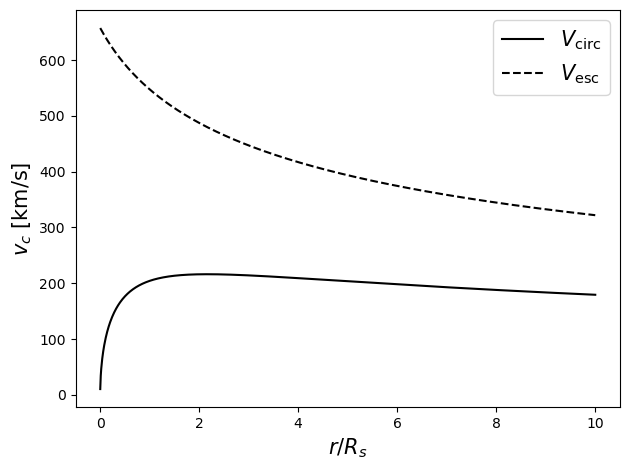

In [18]:

import astropy.units as u
import astropy.constants as cst
import numpy as np
import matplotlib.pyplot as plt

rho_0 = 0.01 * u.M_sun / u.pc**3
R_s = 20 * u.kpc

def NFW_pot(r):
    return -4*np.pi*cst.G*rho_0*R_s**3/r * np.log1p(r/R_s)

def NFW_v_circ(r):
    x = r/R_s
    return np.sqrt(
        4*np.pi*cst.G*rho_0*R_s**2 *
        (np.log1p(x) - x/(1+x)) / x
    )

def NFW_v_esc(r):
    return np.sqrt(-2*NFW_pot(r))

# Avoid r = 0
x = np.linspace(0.001, 10, 1000)
Rs = x * R_s

plt.plot(x, NFW_v_circ(Rs).to_value(u.km/u.s),
         ls="-", color="black", label=r"$V_\mathrm{circ}$")

plt.plot(x, NFW_v_esc(Rs).to_value(u.km/u.s),
         ls="--", color="black", label=r"$V_\mathrm{esc}$")
plt.xlabel(r"$r/R_s$", fontsize=15)
plt.ylabel(r"$v_c$ [km/s]", fontsize=15)
plt.legend(fontsize=15)
plt.tight_layout()
plt.show()
